# Data preprocessing

ILI and ARI are processed separately: set `TARGET` and run the notebook once for each.

- Season: week 40 to week 20 of the next year (33 or 34 weeks); weeks 21-39 belong to no season
- Data from season 2014/15; ERVISS for the EU/EEA, WHO FluID for Switzerland and the UK regions
  (GB = sum of the four regions)
- COVID seasons 2020/21 and 2021/22 (`covid` in `season_info`) and the weeks 2020-W10 to W20 (`covid_week`)
  stay in the data (they are not used in the EWS analyses)
- A season is valid if more than 50% of its weeks are reported
- `value` keeps the original values; `value_clean` has spikes capped, dips raised and gaps of at most
  2 weeks interpolated. Longer gaps stay NaN, zeros are kept

All the computations are in `code/tsfm_europe/preprocess.py` and the settings in `config.yaml`. `python code/data_import.py` does the same without the notebook (this is what the weekly pipeline runs).

## 0. Setup

* Imports

In [1]:
import inspect
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "code"))
from tsfm_europe import preprocess as pp      # all the computations of this notebook
from tsfm_europe.common import load_config

* Directories

In [2]:
TARGET = "ILI"         # "ILI" or "ARI"

RAW = ROOT / "target-data/raw"
PROCESSED = ROOT / "target-data/processed"
FIG_DIR = ROOT / f"figures/preprocessing/{TARGET.lower()}"
PROCESSED.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

cfg = load_config()      # config.yaml: seasons, COVID, FluID locations, cleaning parameters
first_date = pp.iso_sunday(f"{cfg['first_season']}-W{cfg['season_start_week']}")
{k: cfg[k] for k in ["first_season", "season_start_week", "season_end_week", "valid_share", "covid_seasons",
                     "covid_start", "spike_window", "spike_ratio", "spike_min", "max_interpolated_gap"]}

{'first_season': 2014,
 'season_start_week': 40,
 'season_end_week': 20,
 'valid_share': 0.5,
 'covid_seasons': ['2020/21', '2021/22'],
 'covid_start': '2020-W10',
 'spike_window': 4,
 'spike_ratio': 2,
 'spike_min': 10,
 'max_interpolated_gap': 2}

## 1. Load the raw data

- **ERVISS** incidence for the chosen target (EU/EEA countries)
- **WHO FluID** (Switzerland and UK regions)
- **ERVISS** positivity (influenza, RSV, SARS-CoV-2)

In [3]:
erviss, who, pos = pp.load_raw(RAW, TARGET)

for name, d in [(f"ERVISS {TARGET}", erviss), ("WHO FluID", who), ("positivity", pos)]:
    print(f"{name:12} rows: {d.shape[0]:7}  columns: {d.shape[1]}")

ERVISS ILI   rows:   13018  columns: 8
WHO FluID    rows:   14551  columns: 38
positivity   rows:   30739  columns: 12


## 2. Unifying format for all countries

WHO FluID in the ERVISS format (all ages, weeks with both cases and covered population).

In [4]:
fluid = pp.fluid_regions(who, TARGET, cfg)

print("duplicated country + week:", fluid.duplicated(["country_code", "year_week"]).sum())
fluid.groupby("country_code")["year_week"].agg(["min", "max", "count"])

duplicated country + week: 0


,min,max,count
country_code,,,
CH,2009-W28,2026-W43,832
GB-ENG,2020-W01,2026-W43,241
GB-NIR,2020-W01,2026-W43,355
GB-SCT,2020-W01,2026-W40,352
GB-WLS,2020-W01,2026-W43,338


GB as a whole: sum of the cases and of the covered population of the four regions, only weeks where all four reported.

In [5]:
fluid, n_complete, n_dropped = pp.add_gb(fluid, TARGET, cfg)
print(f"GB: {n_complete} weeks with all 4 regions, {n_dropped} weeks dropped")

GB: 233 weeks with all 4 regions, 123 weeks dropped


Incidence per 100,000 and the Sunday of the ISO week, as in ERVISS.

In [6]:
fluid = pp.fluid_to_erviss(fluid, TARGET, erviss.columns, first_date)

print(f"FluID {TARGET}: {len(fluid)} rows, countries: {sorted(fluid['country_code'].unique())}")
fluid.head()

FluID ILI: 2079 rows, countries: ['CH', 'GB', 'GB-ENG', 'GB-NIR', 'GB-SCT', 'GB-WLS']


,indicator,country,country_code,year_week,date,age,value,unit
0,ili,"United Kingdom, England",GB-ENG,2020-W02,2020-01-12,total,14.7,"per 100,000 population"
1,ili,"United Kingdom, England",GB-ENG,2020-W07,2020-02-16,total,8.4,"per 100,000 population"
2,ili,"United Kingdom, England",GB-ENG,2020-W12,2020-03-22,total,9.8,"per 100,000 population"
3,ili,"United Kingdom, England",GB-ENG,2020-W17,2020-04-26,total,3.9,"per 100,000 population"
4,ili,"United Kingdom, England",GB-ENG,2020-W42,2020-10-18,total,1.8,"per 100,000 population"


One table for all countries.

In [7]:
data = pp.combine(erviss, fluid)

print("indicator:", data["indicator"].unique(), "| age:", data["age"].unique())   # kept to tell ILI/ARI and age groups apart
print(f"{TARGET}: {len(data)} rows, {data['location'].nunique()} locations, "
      f"{data['date'].min().date()} to {data['date'].max().date()}")
print("duplicated location + week:", data.duplicated(["location", "date"]).sum())
data.head(15)

indicator: ['ili'] | age: ['total']
ILI: 15097 rows, 32 locations, 2014-10-05 to 2026-10-25
duplicated location + week: 0


,location,country,source,indicator,age,unit,year_week,date,value
0,AT,Austria,ERVISS,ili,total,"per 100,000 population",2014-W40,2014-10-05,589.6
1,AT,Austria,ERVISS,ili,total,"per 100,000 population",2014-W41,2014-10-12,547.3
2,AT,Austria,ERVISS,ili,total,"per 100,000 population",2014-W42,2014-10-19,768.8
3,AT,Austria,ERVISS,ili,total,"per 100,000 population",2014-W43,2014-10-26,696.1
4,AT,Austria,ERVISS,ili,total,"per 100,000 population",2014-W44,2014-11-02,762.6
5,AT,Austria,ERVISS,ili,total,"per 100,000 population",2014-W45,2014-11-09,883.4
6,AT,Austria,ERVISS,ili,total,"per 100,000 population",2014-W46,2014-11-16,744.3
7,AT,Austria,ERVISS,ili,total,"per 100,000 population",2014-W47,2014-11-23,855.5
8,AT,Austria,ERVISS,ili,total,"per 100,000 population",2014-W48,2014-11-30,897.4
9,AT,Austria,ERVISS,ili,total,"per 100,000 population",2014-W49,2014-12-07,982.8


## 3. Regular weekly series

Every location gets every week from 2014-W40 to the last week in the data; weeks that were not reported are NaN.

In [8]:
n_reported = data["value"].notna().sum()
data = pp.regular_grid(data, first_date)

n_weeks = data["date"].nunique()
print(f"weeks per location: {n_weeks} ({data['date'].min().date()} to {data['date'].max().date()})")
print(f"rows: {len(data)} = {data['location'].nunique()} locations x {n_weeks} weeks")
print(f"reported weeks: {data['value'].notna().sum()} (before: {n_reported}), missing weeks: {data['value'].isna().sum()}")
print(f"share of missing weeks: {data['value'].isna().mean() * 100:.2f} %")

weeks per location: 630 (2014-10-05 to 2026-10-25)
rows: 20160 = 32 locations x 630 weeks
reported weeks: 15097 (before: 15097), missing weeks: 5063
share of missing weeks: 25.11 %


## 4. Seasons

`season` (e.g. "2024/25") and `season_week` (week 40 = 1). Weeks 21-39 have no season but are kept,
they are needed for the growth factor, the spike check and the plots.

In [9]:
print(inspect.getsource(pp.add_season))

data = pp.add_covid_week(pp.add_season(data, cfg), cfg)
print("COVID weeks:", data.loc[data["covid_week"], "year_week"].min(), "to",
      data.loc[data["covid_week"], "year_week"].max())

data[["location", "year_week", "date", "season", "season_week", "value"]].head()

def add_season(d, cfg, date_col="date"):
    """`season` (e.g. "2024/25") and `season_week` (week 40 = 1); weeks outside the season get NaN."""
    start_week, end_week = cfg["season_start_week"], cfg["season_end_week"]
    d = d.copy()
    iso = d[date_col].dt.isocalendar()
    week, year = iso["week"].astype(int), iso["year"].astype(int)
    in_season = (week >= start_week) | (week <= end_week)
    start_year = year.where(week >= start_week, year - 1)
    season_start = pd.to_datetime(start_year.astype(str) + f"-W{start_week}-7", format="%G-W%V-%u")
    d["season"] = (start_year.astype(str) + "/" + (start_year + 1).astype(str).str[-2:]).where(in_season)
    d["season_week"] = ((d[date_col] - season_start).dt.days // 7 + 1).where(in_season).astype("Int64")
    return d

COVID weeks: 2020-W10 to 2020-W20


,location,year_week,date,season,season_week,value
0,AT,2014-W40,2014-10-05,2014/15,1,589.6
1,AT,2014-W41,2014-10-12,2014/15,2,547.3
2,AT,2014-W42,2014-10-19,2014/15,3,768.8
3,AT,2014-W43,2014-10-26,2014/15,4,696.1
4,AT,2014-W44,2014-11-02,2014/15,5,762.6


## 5. Season information

One row per location and season: reported weeks, season length, share reported, `valid`,
`finished` (False for the current season) and `covid`. Nothing is removed here.

In [10]:
season_info = pp.make_season_info(data, cfg)

season_info.head()

,location,season,reported_weeks,season_length,share_reported,valid,finished,covid
0,AT,2014/15,26,33,0.79,True,True,False
1,AT,2015/16,26,34,0.76,True,True,False
2,AT,2016/17,27,33,0.82,True,True,False
3,AT,2017/18,28,33,0.85,True,True,False
4,AT,2018/19,25,33,0.76,True,True,False


Valid seasons per location (finished seasons only):

In [11]:
finished = season_info[season_info["finished"]]

(finished.pivot_table(index="location", columns="season", values="valid", aggfunc="first")
 .astype(int)
 .assign(valid_seasons=lambda t: t.sum(axis=1)))

season,2014/15,2015/16,2016/17,2017/18,2018/19,2019/20,2020/21,2021/22,2022/23,2023/24,2024/25,2025/26,valid_seasons
location,,,,,,,,,,,,,
AT,1,1,1,1,1,1,1,1,1,1,1,1,12
BE,1,1,1,1,1,1,1,1,1,1,1,1,12
CH,1,1,1,1,1,1,1,1,1,1,1,1,12
CY,1,1,1,1,1,0,0,0,0,0,0,0,5
CZ,1,1,1,1,1,1,1,1,1,1,1,1,12
DK,1,1,1,1,1,1,1,1,1,1,1,1,12
EE,1,1,1,1,1,1,1,1,1,1,1,1,12
ES,1,1,1,1,1,1,0,0,0,1,1,1,9
FI,0,1,1,1,1,1,0,1,1,1,1,1,10


## 6. Spikes, dips and short gaps

Original values stay in `value`, cleaned values go to `value_clean`:

1. **Spikes**: a week more than 2 times higher than every week in the 4 weeks before and after it (and above 10)
   is capped at the highest of those 8 weeks (`spike_capped`). It is capped, not deleted, as MEM recommends.
2. **Dips**: the mirror rule; a week less than half of every week around it (all above 10) is raised to the
   lowest of those weeks (`dip_raised`).
3. **Short gaps**: gaps of at most 2 weeks with data on both sides are filled by linear interpolation (`imputed`).

`season_info` counts only the weeks really reported, so filled weeks do not make a season valid.

In [12]:
for f in [pp.find_spikes, pp.find_dips, pp.fill_short_gaps, pp.clean]:
    print(inspect.getsource(f))

def find_spikes(s, window, ratio, min_value):
    """A week more than `ratio` times higher than every week in the `window` weeks before and after (and above min_value)."""
    around = pd.concat([s.shift(k) for k in range(-window, window + 1) if k != 0], axis=1)
    cap = around.max(axis=1)
    has_neighbours = s.shift(1).notna() & s.shift(-1).notna()
    return (s > ratio * cap) & (s > min_value) & has_neighbours, cap

def find_dips(s, window, ratio, min_value):
    """The mirror rule: a week less than 1/ratio of every week around it (all above min_value)."""
    around = pd.concat([s.shift(k) for k in range(-window, window + 1) if k != 0], axis=1)
    floor = around.min(axis=1)
    has_neighbours = s.shift(1).notna() & s.shift(-1).notna()
    return (s < floor / ratio) & (floor > min_value) & has_neighbours, floor

def fill_short_gaps(s, max_gap):
    """Linear interpolation of gaps of at most `max_gap` weeks with data on both sides."""
    missing = s.isna()
    gap_id = (missing !=

In [13]:
data = pp.clean(data, cfg)[pp.COLUMNS]

print(f"spikes capped: {data['spike_capped'].sum()}")
print(f"dips raised: {data['dip_raised'].sum()}")
print(f"weeks filled by interpolation: {data['imputed'].sum()}")
print(f"missing weeks: before {data['value'].isna().sum()}, after {data['value_clean'].isna().sum()}")

spikes capped: 11
dips raised: 28
weeks filled by interpolation: 136
missing weeks: before 5063, after 4927


### Before and after: changes per location

In [14]:
changes = data.groupby("location").agg(
    spikes_capped=("spike_capped", "sum"),
    dips_raised=("dip_raised", "sum"),
    weeks_imputed=("imputed", "sum"),
    missing_before=("value", lambda v: v.isna().sum()),
    missing_after=("value_clean", lambda v: v.isna().sum()),
)
changes

,spikes_capped,dips_raised,weeks_imputed,missing_before,missing_after
location,,,,,
AT,0,0,7,311,304
BE,0,2,0,0,0
CH,0,0,0,70,70
CY,0,7,5,388,383
CZ,0,0,1,19,18
DK,0,0,6,118,112
EE,1,5,8,11,3
ES,0,0,0,271,271
FI,0,0,5,127,122


### Before and after: capped spikes

In [15]:
data.loc[data["spike_capped"], ["location", "season", "date", "value", "value_clean"]]

,location,season,date,value,value_clean
4303,EE,2024/25,2024-10-13,562.7,276.0
13995,LU,2016/17,2017-05-07,500.0,0.0
14021,LU,2017/18,2017-11-05,1800.0,400.0
14192,LU,2020/21,2021-02-14,1400.0,500.0
14197,LU,2020/21,2021-03-21,2100.0,500.0
14375,LU,NaN,2024-08-18,3300.0,1600.0
17641,PT,2014/15,2014-10-12,22.6,0.0
17724,PT,2015/16,2016-05-15,18.9,6.5
19495,SI,2025/26,2026-03-01,30.9,11.6
19568,SK,NaN,2015-06-28,996.1,76.1


The 8 weeks before and after every changed week: grey = `value`, blue = `value_clean`, orange = changed week.

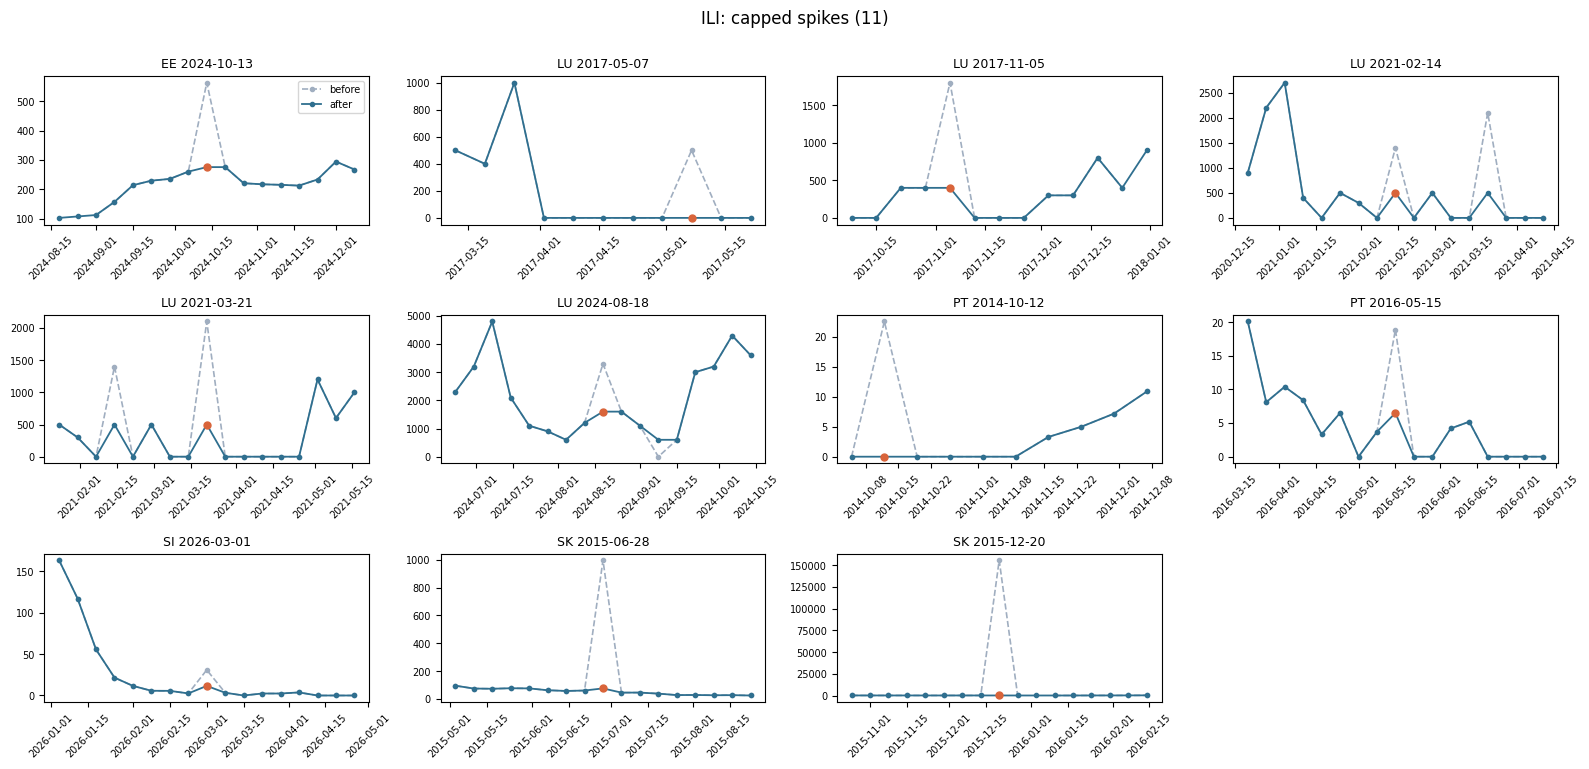

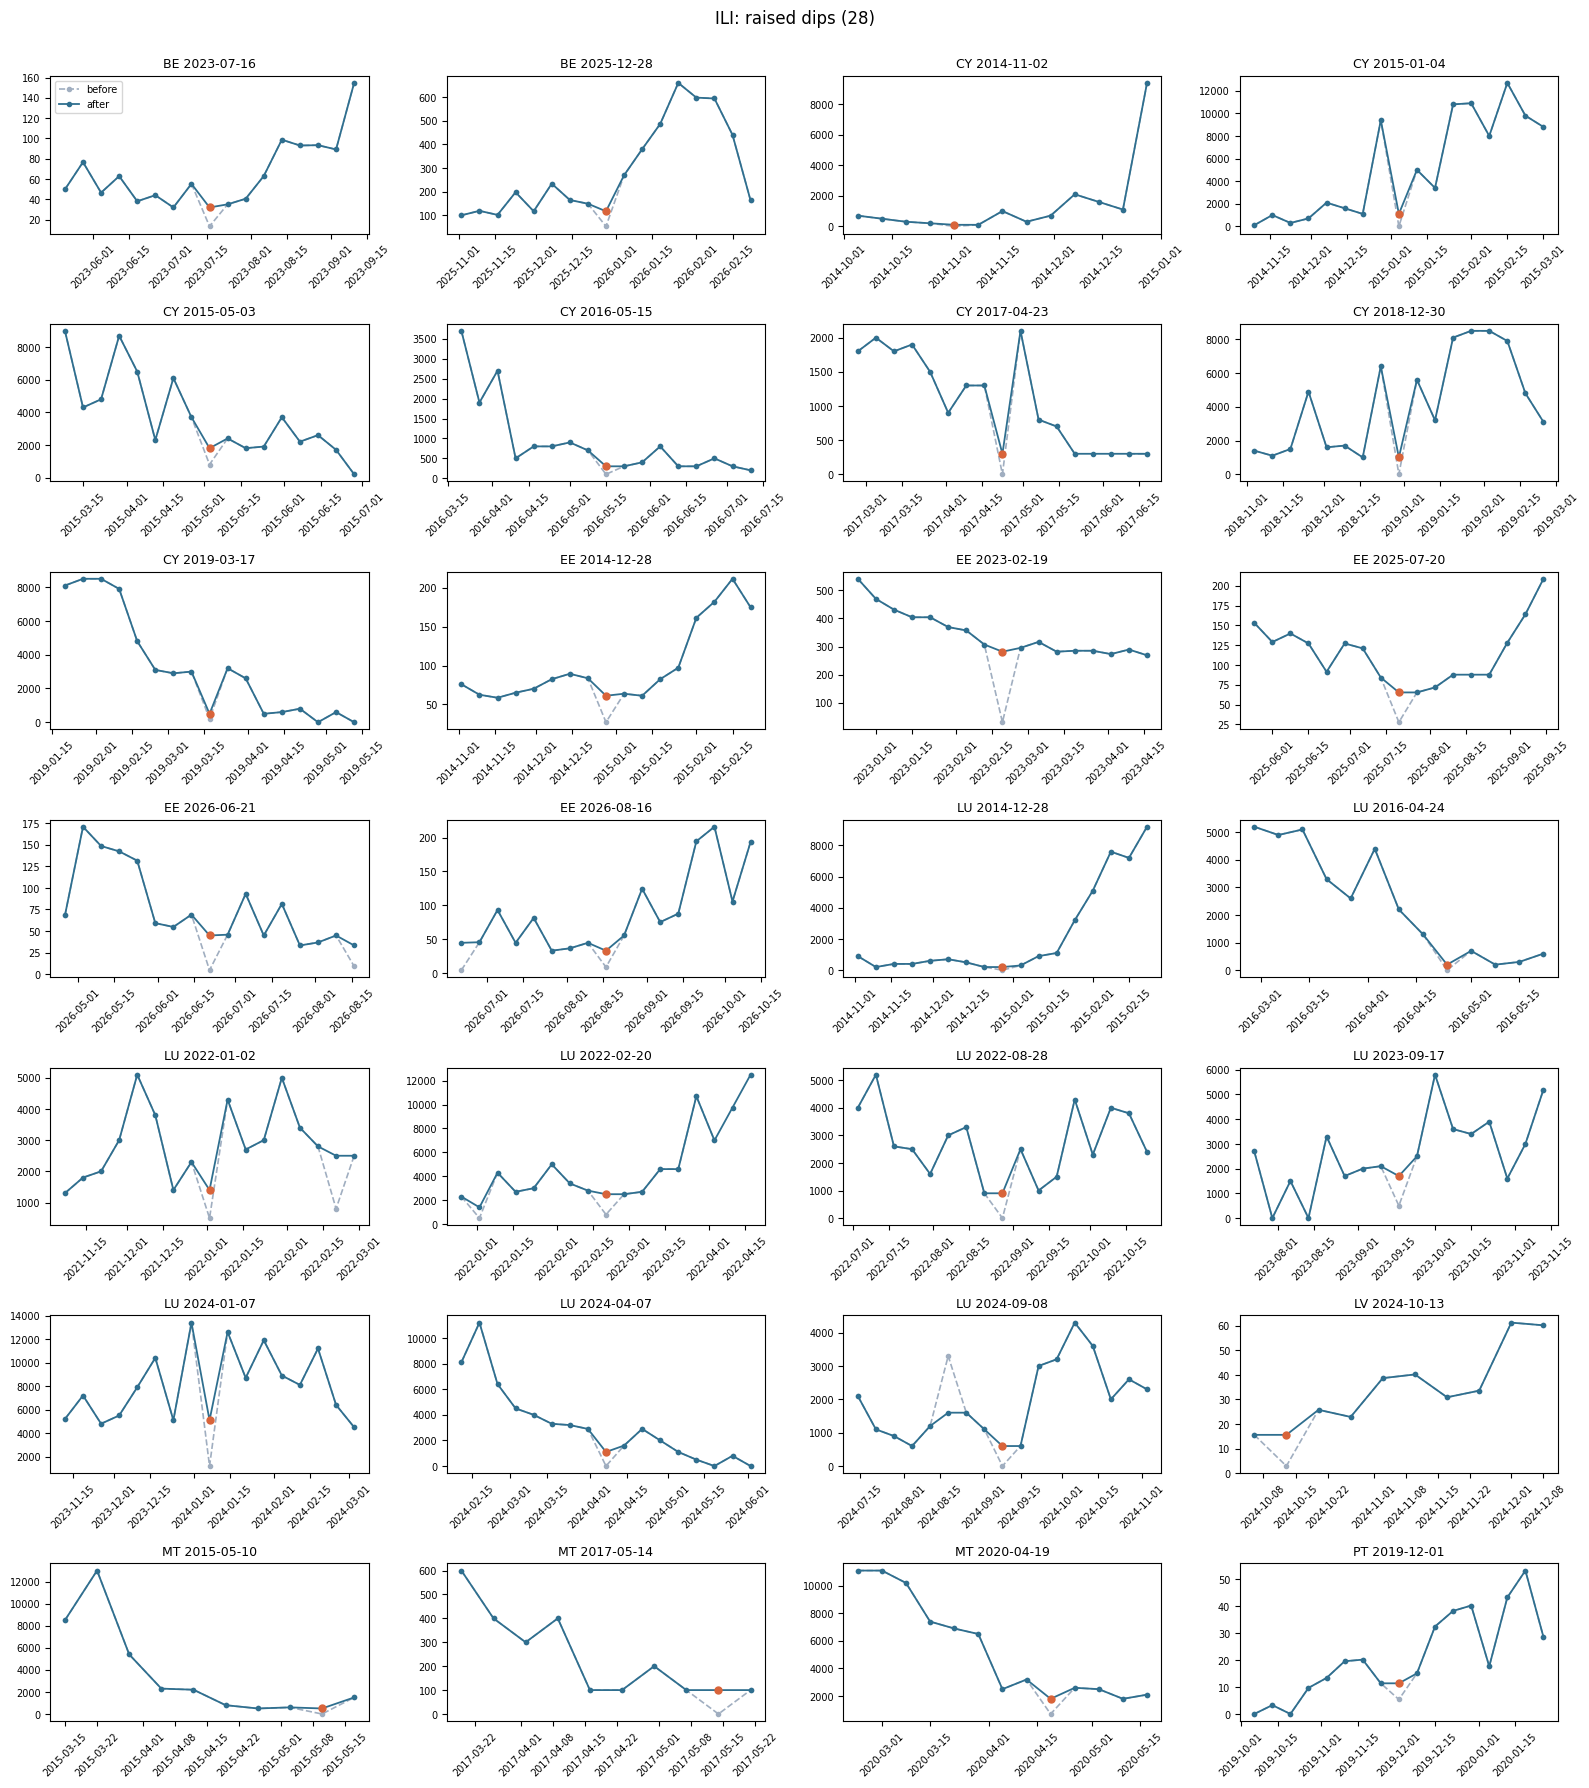

In [16]:
def plot_changes(rows, title, file_name, weeks=8, ncols=4):
    if rows.empty:
        print("nothing to plot")
        return
    nrows = -(-len(rows) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.6 * nrows), squeeze=False)
    for ax, (_, r) in zip(axes.flat, rows.iterrows()):
        d = data[(data["location"] == r["location"])
                 & data["date"].between(r["date"] - pd.Timedelta(weeks=weeks), r["date"] + pd.Timedelta(weeks=weeks))]
        ax.plot(d["date"], d["value"], color="#A0AEC0", linestyle="--", marker=".", linewidth=1.2, label="before")
        ax.plot(d["date"], d["value_clean"], color="#2F6F8F", marker=".", linewidth=1.3, label="after")
        ax.scatter(r["date"], r["value_clean"], color="#D9643A", zorder=3, s=25)
        ax.set_title(f"{r['location']} {r['date'].date()}", fontsize=9)
        ax.tick_params(labelsize=7)
        ax.tick_params(axis="x", rotation=45)
    for ax in axes.flat[len(rows):]:
        ax.set_visible(False)
    axes.flat[0].legend(fontsize=7)
    fig.suptitle(f"{TARGET}: {title} ({len(rows)})", fontsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.98])
    fig.savefig(FIG_DIR / file_name, dpi=110)
    plt.show()


plot_changes(data[data["spike_capped"]], "capped spikes", "capped_spikes.png")
plot_changes(data[data["dip_raised"]], "raised dips", "raised_dips.png")

### Before and after: filled gaps (first 12)

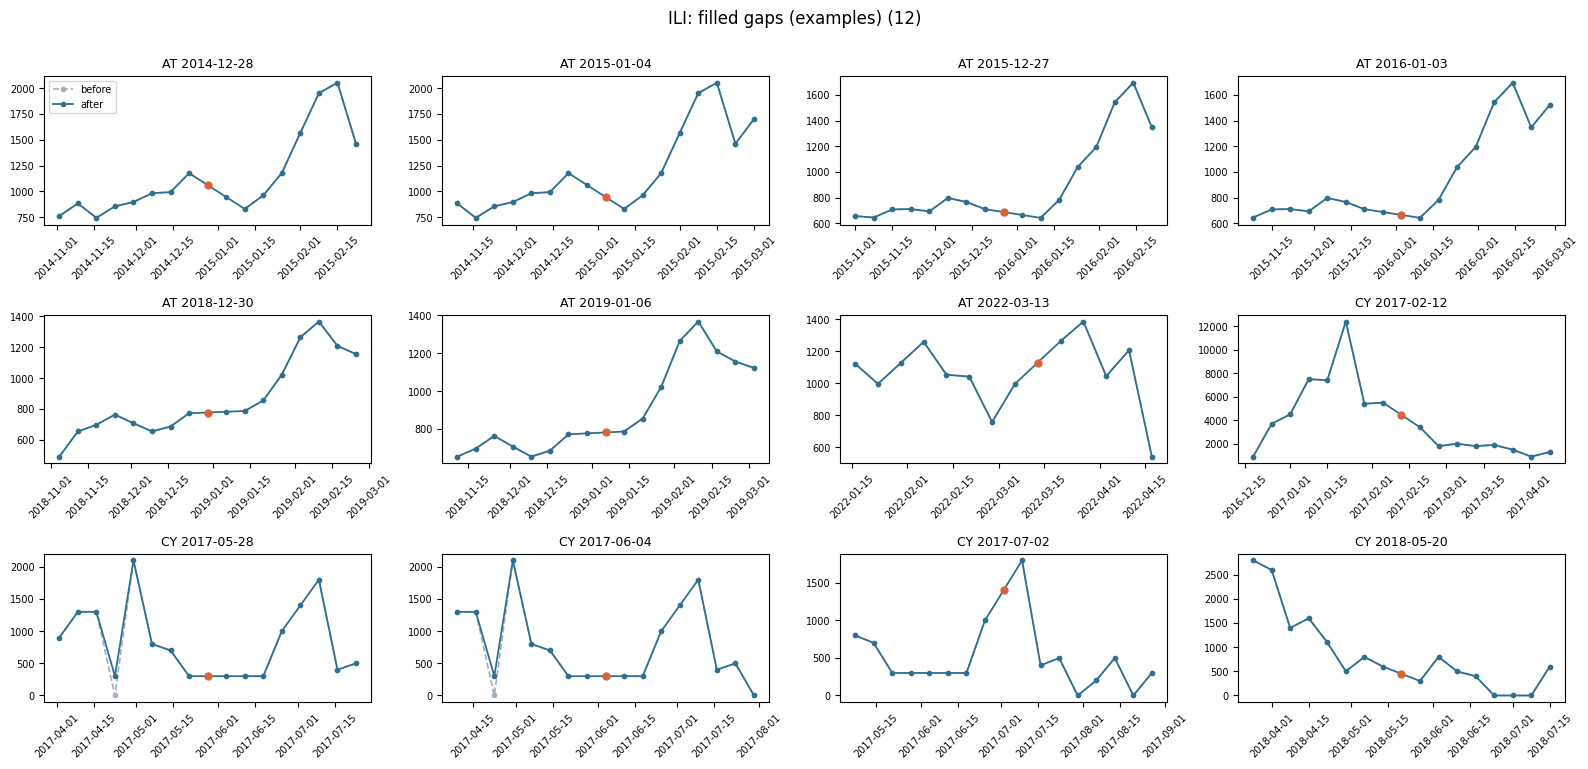

In [17]:
N_EXAMPLES = 12

plot_changes(data[data["imputed"]].head(N_EXAMPLES), "filled gaps (examples)", "filled_gaps.png")

### Before and after: whole series of one location

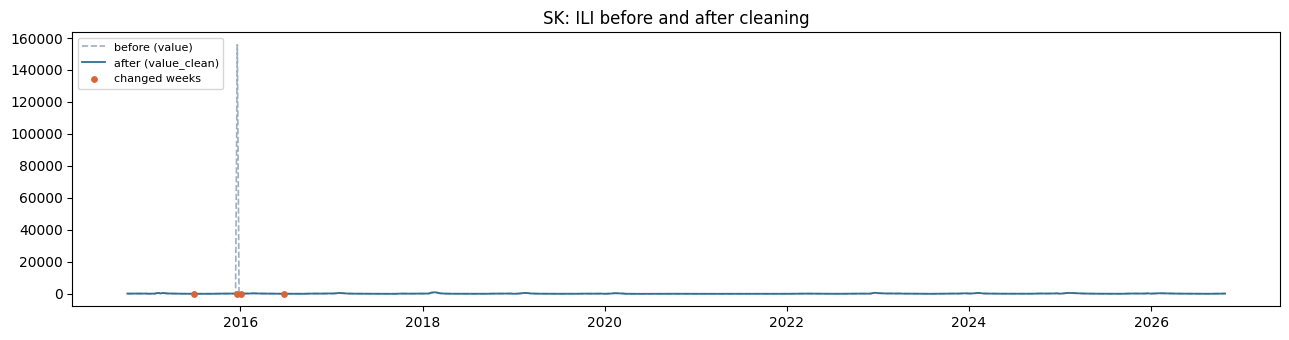

In [18]:
LOCATION = "SK"

d = data[data["location"] == LOCATION]
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(d["date"], d["value"], color="#A0AEC0", linestyle="--", linewidth=1.2, label="before (value)")
ax.plot(d["date"], d["value_clean"], color="#2F6F8F", linewidth=1.3, label="after (value_clean)")
changed = d[d["spike_capped"] | d["dip_raised"] | d["imputed"]]
ax.scatter(changed["date"], changed["value_clean"], color="#D9643A", s=15, zorder=3, label="changed weeks")
ax.set_title(f"{LOCATION}: {TARGET} before and after cleaning")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

## 7. Positivity

ERVISS test positivity for influenza, RSV and SARS-CoV-2 (primary care and hospitals).

In [19]:
print("indicator:", pos["indicator"].unique(), "| age:", pos["age"].unique(), "| unit:", pos["unit"].unique())

positivity = pp.make_positivity(pos, first_date, cfg)

print(f"positivity: {len(positivity)} rows, {positivity['location'].nunique()} locations, "
      f"{positivity['date'].min().date()} to {positivity['date'].max().date()}")
positivity.head()

indicator: ['positivity'] | age: ['total'] | unit: ['%']
positivity: 28202 rows, 29 locations, 2014-10-05 to 2026-10-25


,location,country,pathogen,setting,season,season_week,year_week,date,positivity,tests,detections
0,AT,Austria,Influenza,primary care,2014/15,6,2014-W45,2014-11-09,0.0,1,0
1,AT,Austria,Influenza,primary care,2014/15,7,2014-W46,2014-11-16,0.0,2,0
2,AT,Austria,Influenza,primary care,2014/15,11,2014-W50,2014-12-14,18.2,11,2
3,AT,Austria,Influenza,primary care,2014/15,13,2014-W52,2014-12-28,16.7,6,1
4,AT,Austria,Influenza,primary care,2014/15,14,2015-W01,2015-01-04,33.3,3,1


## 8. Final checks

Checks before saving:
1. one row per location and week
2. the same number of weeks for every location
3. every reported value equals the raw data
4. no reported value lost or added
5. `value_clean` equals `value` except capped spikes, raised dips and filled weeks
6. capped spikes are lower and raised dips higher than before

In [20]:
raw = pd.concat([erviss, fluid], ignore_index=True).rename(columns={"country_code": "location"})
checks = pp.run_checks(data, raw)       # raises AssertionError if a check fails, so wrong data are never saved

for name, result in checks.items():
    print(f"{name}: {result}")
print("All checks passed.")

1. duplicated location + week: 0


2. weeks per location (min, max): (630, 630)
3. values different from raw: 0
4. reported weeks (raw, processed): (15097, 15097)
5. value_clean = value outside the changed weeks: True
6. capped spikes lower, raised dips higher: (np.True_, np.True_)
All checks passed.


## 9. Saving the data

- `<target>.csv`: weekly data of all locations (`value`, `value_clean` and the flags)
- `<target>_season_info.csv`: one row per location and season
- `positivity.csv`: the same for ILI and ARI, overwritten by each run

In [21]:
files = {
    f"{TARGET.lower()}.csv": data,
    f"{TARGET.lower()}_season_info.csv": season_info,
    "positivity.csv": positivity,
}

for name, d in files.items():
    d.to_csv(PROCESSED / name, index=False)
    print(f"saved {name:24} {d.shape[0]:7} rows, {d.shape[1]:2} columns")

saved ili.csv                    20160 rows, 16 columns
saved ili_season_info.csv          416 rows,  8 columns


saved positivity.csv             28202 rows, 11 columns
